# MarketMind — Experiment 3: Causal Wavelet Decomposition

**Goal:** Separate NIFTY 50 returns into lower-frequency (trend-like) and higher-frequency (short-term fluctuation) components, then measure whether the resulting features are useful for later regime modelling.

This notebook uses the same bundled 1-minute OHLC CSVs, session-aware 15-minute bars, and chronological 70/30 split as the baseline and HMM experiments.

### Important methodological rules
- A wavelet transform over a complete series can use future observations around a timestamp. **We do not do that.** Each feature is computed from a trailing window ending at the timestamp being described.
- The current observation is included; no later observation is used.
- Train/test split is chronological. Any scaling is fitted on training data only.
- Wavelet features are not regime labels and this experiment does not claim trading profitability.
- The 15-second files are not mixed with the 1-minute history; we retain the same 15-minute bar basis for comparability.

## 0. Install the additional dependency

Run this cell once. If needed, restart the kernel and run all cells from the top.

In [1]:
%pip install PyWavelets

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and automatic project-folder detection

Keep this notebook inside `MarketMind/research/`. The project root is detected automatically; no manual Windows path is required.

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
WAVELET = "haar"
LEVEL = 3
WINDOW = 16                 # trailing 16 x 15-minute returns; about 4 trading hours
MIN_VALID_ROWS = WINDOW + 10

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ROOT = next((p for p in candidates if (p / "data" / "raw" / "nifty50" / "1min").is_dir()), None)
if ROOT is None:
    # Support launching Jupyter from the parent folder containing MarketMind.
    for parent in [cwd, *cwd.parents]:
        candidate = parent / "MarketMind"
        if (candidate / "data" / "raw" / "nifty50" / "1min").is_dir():
            ROOT = candidate
            break
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate MarketMind/data/raw/nifty50/1min. "
        f"Notebook working directory: {cwd}. Keep this notebook in MarketMind/research."
    )

DATA_DIR = ROOT / "data" / "raw" / "nifty50" / "1min"
OUT_DIR = ROOT / "research" / "wavelet_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)
files = sorted(DATA_DIR.rglob("*.csv"))
print("Project root:", ROOT)
print("Data folder:", DATA_DIR)
print("1-minute CSV files:", len(files))
if not files:
    raise FileNotFoundError(f"No 1-minute CSVs found under {DATA_DIR}")
print("Wavelet:", WAVELET, "| level:", LEVEL, "| trailing window:", WINDOW)

Project root: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind
Data folder: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min
1-minute CSV files: 20
Wavelet: haar | level: 3 | trailing window: 16


## 2. Load, validate and resample NIFTY data

This follows the same cleaning and session-aware 15-minute resampling approach used in the HMM experiment. Each trading day is resampled independently so bars do not cross overnight gaps.

In [3]:
frames, file_audit = [], []
required = ["Timestamp", "Open", "High", "Low", "Close"]
for path in files:
    df = pd.read_csv(path)
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"Skipping {path.name}: missing {missing}")
        continue
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    for col in ["Open", "High", "Low", "Close"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    frames.append(df)
    file_audit.append({"file": str(path.relative_to(ROOT)), "rows": len(df),
                       "start": str(df["Timestamp"].min()), "end": str(df["Timestamp"].max())})
if not frames:
    raise ValueError("No CSV files with the required OHLC columns were loaded.")

raw = pd.concat(frames, ignore_index=True).sort_values("Timestamp")
raw = raw.dropna(subset=required)
raw = raw.drop_duplicates(subset=["Timestamp"], keep="first")
raw = raw[(raw[["Open", "High", "Low", "Close"]] > 0).all(axis=1)]
raw = raw[raw["High"] >= raw[["Open", "Close", "Low"]].max(axis=1)]
raw = raw[raw["Low"] <= raw[["Open", "Close", "High"]].min(axis=1)]
raw = raw.set_index("Timestamp").sort_index().between_time("09:15", "15:29").copy()
raw["session_date"] = raw.index.date

def resample_session(day):
    day = day.drop(columns=["session_date"])
    return day.resample("15min", origin="start_day", offset="9h15min",
                        label="left", closed="left").agg({
        "Open": "first", "High": "max", "Low": "min", "Close": "last"
    }).dropna(subset=["Open", "High", "Low", "Close"])

bars = pd.concat([resample_session(g) for _, g in raw.groupby("session_date")]).sort_index()
bars = bars[(bars.index.time >= pd.Timestamp("09:15").time()) &
            (bars.index.time <= pd.Timestamp("15:15").time())]
print(f"Loaded {len(file_audit)} files | cleaned 1m rows: {len(raw):,} | 15m bars: {len(bars):,}")
print("Coverage:", bars.index.min(), "to", bars.index.max())
display(pd.DataFrame(file_audit).head())
display(bars.head())

Loaded 20 files | cleaned 1m rows: 890,607 | 15m bars: 59,378
Coverage: 2017-04-03 09:15:00 to 2026-11-17 15:15:00


,file,rows,start,end
0,data\raw\nifty50\1min\2017\NIFTY50_1min_2017.csv,69375,2017-04-03 09:15:00,2017-12-29 15:29:00
1,data\raw\nifty50\1min\2018\NIFTY50_1min_2018.csv,91874,2018-01-01 09:15:00,2018-12-31 15:29:00
2,data\raw\nifty50\1min\2019\NIFTY50_1min_2019.csv,91500,2019-01-01 09:15:00,2019-12-31 15:29:00
3,data\raw\nifty50\1min\2020\NIFTY50_1min_2020.csv,94125,2020-01-01 09:15:00,2020-12-31 15:29:00
4,data\raw\nifty50\1min\2021\NIFTY50_1min_2021.csv,92668,2021-01-01 09:15:00,2021-12-31 15:29:00


,Open,High,Low,Close
Timestamp,,,,
2017-04-03 09:15:00,9219.63,9221.75,9193.50,9200.35
2017-04-03 09:30:00,9200.65,9208.80,9195.35,9197.50
2017-04-03 09:45:00,9197.80,9205.60,9192.40,9202.35
2017-04-03 10:00:00,9202.05,9209.35,9201.90,9205.90
2017-04-03 10:15:00,9205.90,9207.20,9198.85,9201.30


## 3. Define the causal rolling wavelet feature extractor

For every timestamp, we take only the trailing `WINDOW` log returns ending at that timestamp. We apply a discrete wavelet decomposition to that window. The approximation component represents slower movement; detail coefficients represent faster fluctuations at different scales. Because an NSE session contains only about 25 fifteen-minute bars, the window is 16 bars (about four trading hours) and is reset at each session.

The transform is recomputed on a trailing window at each timestamp. This is more computationally expensive than a single whole-series transform, but it avoids using future samples to construct the current feature. Boundary effects still exist and are a limitation of finite-window wavelet analysis.

In [4]:
def decompose_trailing_window(values, wavelet=WAVELET, level=LEVEL):
    """Return causal wavelet summaries for a window ending at the current bar."""
    values = np.asarray(values, dtype=float)
    coeffs = pywt.wavedec(values, wavelet=wavelet, mode="symmetric", level=level)
    # Reconstruct approximation-only signal by zeroing every detail coefficient.
    approx_coeffs = [coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]]
    approx = pywt.waverec(approx_coeffs, wavelet=wavelet, mode="symmetric")[:len(values)]
    detail_coeffs = coeffs[1:]  # ordered D_level ... D1
    energies = [float(np.sqrt(np.mean(c ** 2))) if len(c) else 0.0 for c in detail_coeffs]
    high_energy = float(np.sqrt(np.mean(np.concatenate([c.ravel() for c in detail_coeffs]) ** 2)))
    low_energy = float(np.sqrt(np.mean(approx ** 2)))
    low_slope = float(np.polyfit(np.arange(len(approx)), approx, 1)[0])
    ratio = high_energy / (low_energy + 1e-12)
    return {
        "wavelet_low_last": float(approx[-1]),
        "wavelet_low_mean": float(np.mean(approx)),
        "wavelet_low_slope": low_slope,
        "wavelet_detail_d3_energy": energies[0],
        "wavelet_detail_d2_energy": energies[1],
        "wavelet_detail_d1_energy": energies[2],
        "wavelet_high_energy": high_energy,
        "wavelet_high_low_ratio": ratio,
    }

# Sanity check: the chosen level must be supported by the window length.
max_level = pywt.dwt_max_level(WINDOW, pywt.Wavelet(WAVELET).dec_len)
if LEVEL > max_level:
    raise ValueError(f"LEVEL={LEVEL} exceeds maximum supported level {max_level} for this window/wavelet.")
print("Maximum supported decomposition level:", max_level)
print("Example feature vector:", decompose_trailing_window(np.random.default_rng(RANDOM_STATE).normal(size=WINDOW)))

Maximum supported decomposition level: 4
Example feature vector: {'wavelet_low_last': 0.19860420113899563, 'wavelet_low_mean': -0.05606464936680505, 'wavelet_low_slope': 0.04793766597756248, 'wavelet_detail_d3_energy': 1.0993471292740222, 'wavelet_detail_d2_energy': 1.229284087847837, 'wavelet_detail_d1_energy': 0.6153649509716094, 'wavelet_high_energy': 0.9059753181321044, 'wavelet_high_low_ratio': 3.474270331034641}


## 4. Compute causal wavelet features

Features are computed on log returns, not raw index levels, so the scale of the index itself does not dominate the decomposition. The first `WINDOW - 1` rows are unavailable because there is not yet a full trailing window.

In [5]:
# Calculate returns within each trading session. This avoids treating the
# overnight close-to-open gap as an ordinary 15-minute return or carrying a
# rolling wavelet window across sessions.
log_returns = bars.groupby(bars.index.date)["Close"].transform(lambda s: np.log(s).diff())
feature_rows = []
feature_index = []
started = time.time()
session_return_arrays = []
for session_date, session_returns in log_returns.groupby(log_returns.index.date):
    session_values = session_returns.to_numpy(dtype=float)
    session_return_arrays.append(session_values)
    for end in range(WINDOW - 1, len(session_values)):
        window_values = session_values[end - WINDOW + 1:end + 1]
        if not np.isfinite(window_values).all():
            continue
        feature_rows.append(decompose_trailing_window(window_values))
        feature_index.append(session_returns.index[end])

wavelet_features = pd.DataFrame(feature_rows, index=pd.DatetimeIndex(feature_index))
wavelet_features = wavelet_features.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Computed {len(wavelet_features):,} causal wavelet feature rows in {time.time()-started:.1f}s")
print("Feature columns:", list(wavelet_features.columns))
display(wavelet_features.describe().T)

Computed 21,366 causal wavelet feature rows in 18.6s
Feature columns: ['wavelet_low_last', 'wavelet_low_mean', 'wavelet_low_slope', 'wavelet_detail_d3_energy', 'wavelet_detail_d2_energy', 'wavelet_detail_d1_energy', 'wavelet_high_energy', 'wavelet_high_low_ratio']


,count,mean,std,min,25%,50%,75%,max
wavelet_low_last,21366.0,-5.312765e-06,0.000510,-0.005220,-0.000228,1.401158e-05,0.000229,0.006956
wavelet_low_mean,21366.0,-5.553679e-06,0.000389,-0.002983,-0.000173,-5.232001e-07,0.000165,0.009576
wavelet_low_slope,21366.0,4.534854e-08,0.000063,-0.001152,-0.000029,1.922186e-07,0.000030,0.001106
wavelet_detail_d3_energy,21366.0,9.877084e-04,0.000939,0.000005,0.000460,7.727913e-04,0.001240,0.025386
wavelet_detail_d2_energy,21366.0,1.041661e-03,0.000850,0.000051,0.000578,8.545403e-04,0.001268,0.029038
wavelet_detail_d1_energy,21366.0,1.089377e-03,0.000795,0.000031,0.000660,9.174049e-04,0.001294,0.022236
wavelet_high_energy,21366.0,1.099228e-03,0.000783,0.000141,0.000679,9.298867e-04,0.001294,0.018893
wavelet_high_low_ratio,21366.0,4.820426e+00,7.883227,0.605829,2.271474,3.246111e+00,5.103994,492.764820


## 5. Visualise low- and high-frequency components

The example plot shows one contiguous trading segment. The lower-frequency approximation is the slow component reconstructed from the trailing window; the high-frequency energy summarises detail coefficients. These are features, not direct buy/sell signals.

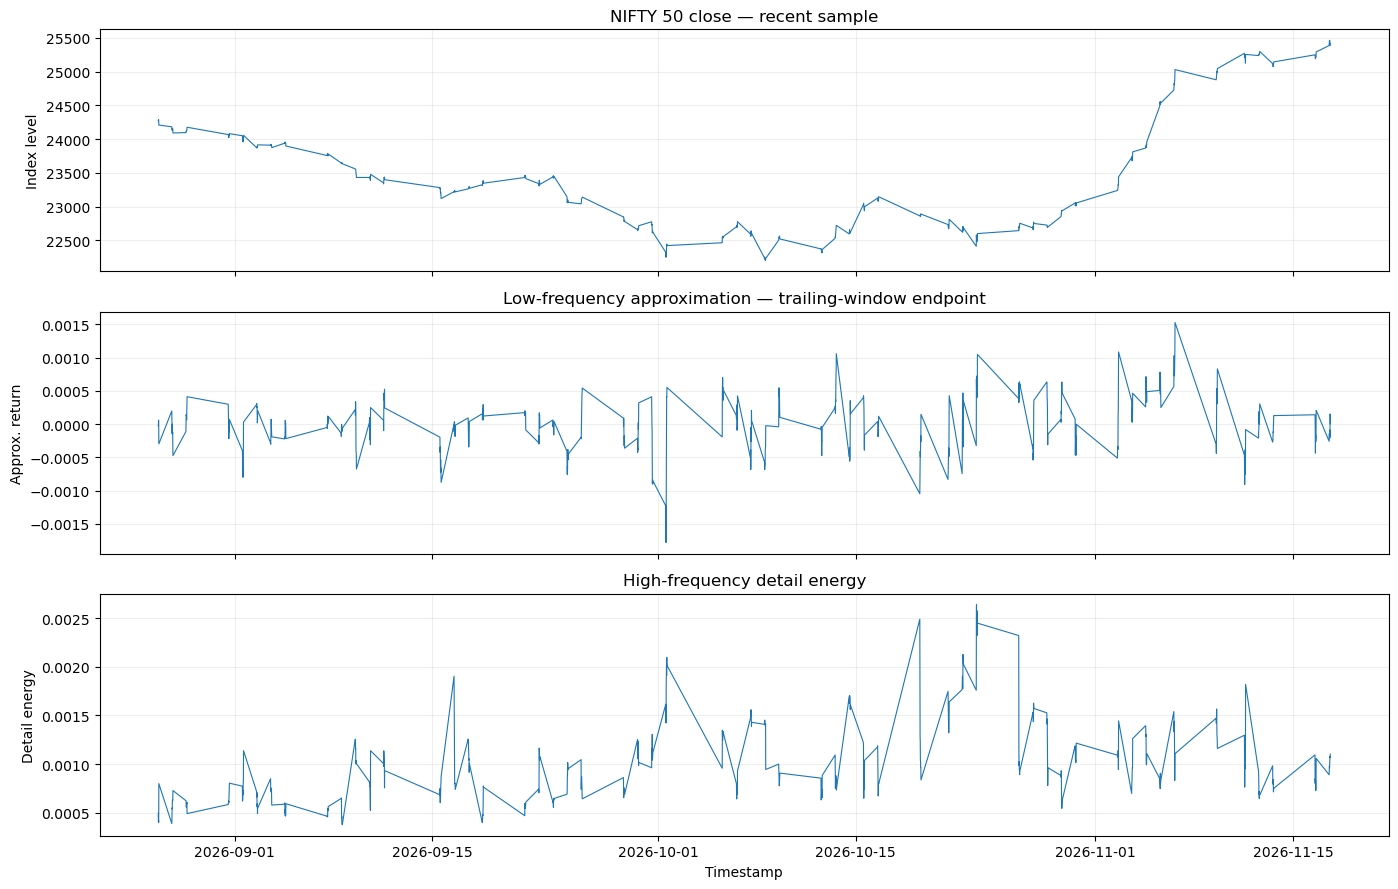

In [6]:
# Select a recent contiguous sample from the available feature data.
plot_n = min(500, len(wavelet_features))
plot_idx = wavelet_features.index[-plot_n:]
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(bars.loc[plot_idx, "Close"], linewidth=0.8)
axes[0].set_title("NIFTY 50 close — recent sample")
axes[0].set_ylabel("Index level")
axes[1].plot(wavelet_features.loc[plot_idx, "wavelet_low_last"], linewidth=0.8)
axes[1].set_title("Low-frequency approximation — trailing-window endpoint")
axes[1].set_ylabel("Approx. return")
axes[2].plot(wavelet_features.loc[plot_idx, "wavelet_high_energy"], linewidth=0.8)
axes[2].set_title("High-frequency detail energy")
axes[2].set_ylabel("Detail energy")
axes[2].set_xlabel("Timestamp")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 6. Causality / no-future-data check

We verify that the feature values for an earlier prefix are unchanged if later observations are appended. This is a practical test of the trailing-window implementation. It does not eliminate all wavelet boundary effects, but it checks that future rows are not consulted.

In [7]:
# Use one session for this test, so the check mirrors the per-session feature logic.
causal_values = next((a for a in session_return_arrays if len(a) > WINDOW + 3), None)
if causal_values is None:
    raise ValueError("No sufficiently long session available for the causality check.")
cut = WINDOW + 1
# Compute a small prefix once, then compare it with the same prefix when future data exists.
def features_for_prefix(arr):
    out = []
    for end in range(WINDOW - 1, len(arr)):
        w = arr[end-WINDOW+1:end+1]
        if np.isfinite(w).all(): out.append(decompose_trailing_window(w))
    return pd.DataFrame(out)

prefix_a = features_for_prefix(causal_values[:cut])
prefix_b = features_for_prefix(causal_values[:min(cut + 3, len(causal_values))]).iloc[:len(prefix_a)]
causal_max_abs_diff = float(np.max(np.abs(prefix_a.to_numpy() - prefix_b.to_numpy())))
print("Max absolute difference after appending future observations:", causal_max_abs_diff)
assert causal_max_abs_diff < 1e-10, "Causality check failed: earlier features changed when future data was appended."
print("Causality check passed: appended future observations did not change prior features.")

Max absolute difference after appending future observations: 0.0
Causality check passed: appended future observations did not change prior features.


## 7. Chronological split and feature scaling

We retain the chronological 70/30 split. The scaler is fitted only on the training period. The held-out period remains untouched for subsequent model experiments.

In [8]:
split_at = int(len(wavelet_features) * TRAIN_FRACTION)
train_features = wavelet_features.iloc[:split_at].copy()
test_features = wavelet_features.iloc[split_at:].copy()
scaler = StandardScaler()
Z_train = scaler.fit_transform(train_features)
Z_test = scaler.transform(test_features)

split_summary = pd.DataFrame([
    {"partition": "train", "rows": len(train_features), "start": str(train_features.index.min()), "end": str(train_features.index.max())},
    {"partition": "test", "rows": len(test_features), "start": str(test_features.index.min()), "end": str(test_features.index.max())},
])
display(split_summary)
print("Scaled train shape:", Z_train.shape, "| scaled test shape:", Z_test.shape)

,partition,rows,start,end
0,train,14956,2017-04-03 13:15:00,2023-12-27 14:45:00
1,test,6410,2023-12-27 15:00:00,2026-11-17 15:15:00


Scaled train shape: (14956, 8) | scaled test shape: (6410, 8)


## 8. Compare low- and high-frequency feature behaviour

This is descriptive analysis, not a supervised test: there are no independently labelled market regimes in the dataset. We compare distributions and correlations to understand what information the wavelet features encode.

,wavelet_low_last,wavelet_low_mean,wavelet_low_slope,wavelet_detail_d3_energy,wavelet_detail_d2_energy,wavelet_detail_d1_energy,wavelet_high_energy,wavelet_high_low_ratio
wavelet_low_last,1.000,0.756,0.648,0.005,0.006,0.008,0.011,0.000
wavelet_low_mean,0.756,1.000,-0.008,0.070,0.067,0.070,0.086,-0.002
wavelet_low_slope,0.648,-0.008,1.000,-0.075,-0.070,-0.069,-0.082,0.003
wavelet_detail_d3_energy,0.005,0.070,-0.075,1.000,0.631,0.639,0.777,-0.003
wavelet_detail_d2_energy,0.006,0.067,-0.070,0.631,1.000,0.711,0.869,-0.002
wavelet_detail_d1_energy,0.008,0.070,-0.069,0.639,0.711,1.000,0.949,0.008
wavelet_high_energy,0.011,0.086,-0.082,0.777,0.869,0.949,1.000,0.004
wavelet_high_low_ratio,0.000,-0.002,0.003,-0.003,-0.002,0.008,0.004,1.000


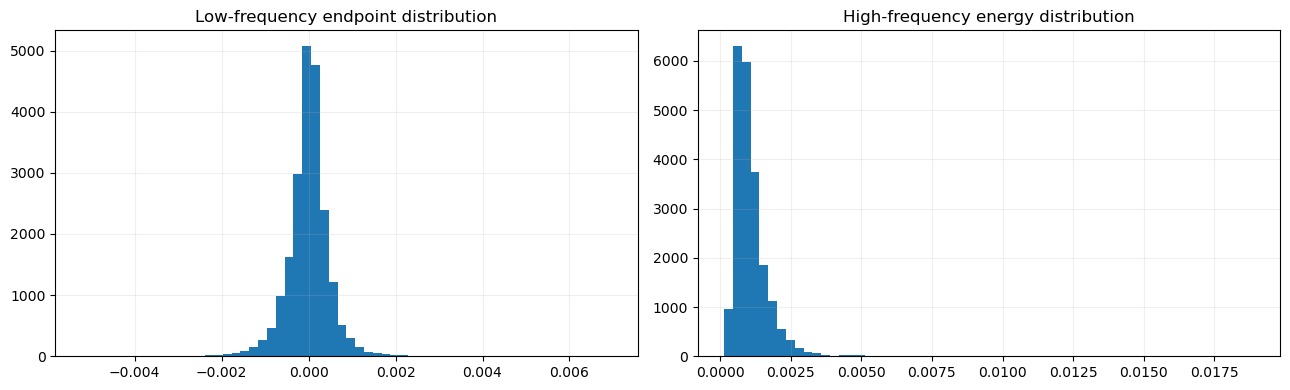

In [9]:
low_cols = ["wavelet_low_last", "wavelet_low_mean", "wavelet_low_slope"]
high_cols = ["wavelet_detail_d3_energy", "wavelet_detail_d2_energy", "wavelet_detail_d1_energy", "wavelet_high_energy", "wavelet_high_low_ratio"]
summary = pd.DataFrame({
    "low_frequency_mean_abs": wavelet_features[low_cols].abs().mean(),
    "high_frequency_mean_abs": wavelet_features[high_cols].abs().mean(),
})
display(wavelet_features[low_cols + high_cols].corr().round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
wavelet_features["wavelet_low_last"].hist(bins=60, ax=axes[0])
axes[0].set_title("Low-frequency endpoint distribution")
wavelet_features["wavelet_high_energy"].hist(bins=60, ax=axes[1])
axes[1].set_title("High-frequency energy distribution")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 9. Save features, summaries and experiment metadata

These outputs will be inputs to Experiment 4 (dual-scale temporal learning). Keep the low- and high-frequency features separate as well as combined.

In [10]:
wavelet_features.to_csv(OUT_DIR / "causal_wavelet_features.csv", index_label="Timestamp")
train_features.to_csv(OUT_DIR / "causal_wavelet_train_features.csv", index_label="Timestamp")
test_features.to_csv(OUT_DIR / "causal_wavelet_test_features.csv", index_label="Timestamp")
feature_summary = wavelet_features.describe().T
feature_summary.to_csv(OUT_DIR / "wavelet_feature_summary.csv")

metadata = {
    "experiment": "Causal rolling-window wavelet decomposition",
    "dataset": "Bundled NIFTY 50 1-minute OHLC CSV files",
    "bar_interval": "15min",
    "wavelet": WAVELET,
    "decomposition_level": LEVEL,
    "trailing_window_bars": WINDOW,
    "input_series": "15-minute log returns",
    "feature_columns": list(wavelet_features.columns),
    "train_fraction": TRAIN_FRACTION,
    "train_rows": int(len(train_features)),
    "test_rows": int(len(test_features)),
    "train_start": str(train_features.index.min()),
    "train_end": str(train_features.index.max()),
    "test_start": str(test_features.index.min()),
    "test_end": str(test_features.index.max()),
    "causality_prefix_max_abs_difference": causal_max_abs_diff,
    "causality_check_passed": bool(causal_max_abs_diff < 1e-10),
    "limitations": [
        "Wavelet features are causal trailing-window summaries, not ground-truth regimes.",
        "Finite-window boundary effects remain and depend on wavelet and window choice.",
        "No supervised accuracy metric is available because independent regime labels are absent.",
        "No trading profitability claim is made; transaction-cost-aware walk-forward testing is still required.",
        "The chosen wavelet, level and window are research hyperparameters and should be sensitivity-tested."
    ]
}
(OUT_DIR / "wavelet_experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved outputs to:", OUT_DIR.resolve())
for p in sorted(OUT_DIR.iterdir()): print(" -", p.name)

Saved outputs to: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\wavelet_results
 - causal_wavelet_features.csv
 - causal_wavelet_test_features.csv
 - causal_wavelet_train_features.csv
 - wavelet_experiment_metadata.json
 - wavelet_feature_summary.csv


## 10. Interpretation and next experiment

- `wavelet_low_*` features summarise slower movement in the trailing return window.
- `wavelet_detail_*_energy` and `wavelet_high_energy` summarise faster fluctuations.
- `wavelet_high_low_ratio` measures high-frequency energy relative to low-frequency energy; it is not a probability.
- The next experiment should combine the low- and high-frequency feature groups and test whether they improve a temporal regime model (for example, a Gaussian HMM) on the same chronological folds.
